# WTS — przygotowanie danych i pierwszy eksperyment ML

Notebook do pracy krok po kroku na plikach `scenario_ml_frames.csv` przygotowanych z istniejącego pipeline'u.

**Kolejność:** konfiguracja → odczyt → walidacja → podsumowanie danych → etykiety → podział według zdarzeń → pierwszy model → porównanie z regułami.

**Ważne:** jednostką obserwacji jest *klatka*, ale jednostką podziału na zbiory jest `source_event_id`. Model nie otrzymuje etykiety, wyniku reguł ani identyfikatorów jako cech.

Komórki modelowania nie trenują niczego bez etykiet `risk_gt` obu klas i dostatecznej liczby niezależnych grup.

In [70]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# Ścieżki są liczone względem ROOT, niezależnie od katalogu uruchomienia notebooka.
# Jeśli notebook leży w katalogu notebooks/, użyj ROOT = Path("..").resolve()
ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path.cwd().resolve()
OUTPUTS_DIR = ROOT / "outputs"
FILE_NAME = "scenario_ml_frames.csv"
# LABELS_CSV = None  # np. ROOT / "annotations" / "frame_labels.csv"
LABELS_CSV = "frame_labels.csv"
ARTIFACTS_DIR = ROOT / "outputs" / "ml_experiment"

# Kontrola: ustaw True, gdy chcesz zastąpić istniejące pliki wynikowe
OVERWRITE = False

FEATURES = [
    "num_pedestrians", "num_vehicles", "num_interactions",
    "num_pedestrians_crossing", "num_pedestrians_waiting",
    "num_vehicles_approaching", "num_vehicles_stopped",
    "min_ttc_s", "min_distance_crosswalk_m",
    "max_vehicle_speed_kmh", "mean_vehicle_speed_kmh",
    "num_ttc_available", "min_pedestrian_vehicle_distance_m",
]
KEY = ["video_id", "frame_idx"]
print("ROOT:", ROOT)
print("OUTPUTS_DIR:", OUTPUTS_DIR)


ROOT: /Users/maja/Documents/magisterka/Traffic-Threat-Detection-MSc
OUTPUTS_DIR: /Users/maja/Documents/magisterka/Traffic-Threat-Detection-MSc/outputs


## 1. Znajdź pliki z poszczególnych nagrań
W przypadku braku plików sprawdź `ROOT` i `OUTPUTS_DIR`. Pliki można też przekopiować do jednego katalogu pod `outputs/`.

In [71]:
paths = sorted(OUTPUTS_DIR.rglob(FILE_NAME)) if OUTPUTS_DIR.exists() else []
print(f"Znaleziono {len(paths)} plików {FILE_NAME}")
display(pd.DataFrame({"path": [str(p.relative_to(ROOT)) for p in paths]}))
if not paths:
    print("Brak plików — sprawdź ścieżki i uruchom ponownie od tej komórki.")


Znaleziono 8 plików scenario_ml_frames.csv


,path
0,outputs/20230707_12_SN17_T1/csv/scenario_ml_fr...
1,outputs/20230707_19_CN8_T1/csv/scenario_ml_fra...
2,outputs/20230728_31_CN37_T1/csv/scenario_ml_fr...
3,outputs/20230728_32_CN4_T1/csv/scenario_ml_fra...
4,outputs/20230728_37_CN38_T2/csv/scenario_ml_fr...
5,outputs/20230922_16_CN5_T1/csv/scenario_ml_fra...
6,outputs/20230922_37_CN9_T1/csv/scenario_ml_fra...
7,outputs/20230922_42_CN37_T1/csv/scenario_ml_fr...


## 2. Połącz dane i sprawdź schemat
Przerywamy przy powtarzających się kluczach lub niezgodnych identyfikatorach zamiast po cichu scalać niepewne rekordy.

In [72]:
REQUIRED = set(KEY + ["source_event_id", "timestamp_s", "pipeline_ok", "rule_pred"] + FEATURES)
frames_list = []
for path in paths:
    df = pd.read_csv(path, low_memory=False)
    absent = REQUIRED - set(df.columns)
    if absent:
        raise ValueError(f"{path}: brak kolumn: {sorted(absent)}")
    if df[KEY].isna().any().any():
        raise ValueError(f"{path}: brak video_id lub frame_idx")
    if df["source_event_id"].isna().any():
        raise ValueError(f"{path}: brak source_event_id — uzupełnij przed łączeniem")
    if df.duplicated(KEY).any():
        raise ValueError(f"{path}: duplikaty video_id + frame_idx")
    df["source_file"] = str(path.relative_to(ROOT))
    frames_list.append(df)

all_frames = pd.concat(frames_list, ignore_index=True) if frames_list else pd.DataFrame()
if not all_frames.empty:
    if all_frames.duplicated(KEY).any():
        examples = all_frames.loc[all_frames.duplicated(KEY, keep=False), KEY + ["source_file"]].head()
        raise ValueError(f"Te same klatki w różnych plikach:\n{examples}")
    for col in FEATURES + ["timestamp_s", "frame_idx", "pipeline_ok", "rule_pred"]:
        all_frames[col] = pd.to_numeric(all_frames[col], errors="coerce")
    if not all_frames["rule_pred"].dropna().isin([0,1]).all():
        raise ValueError("rule_pred musi być 0/1 (lub brak)")
    all_frames = all_frames.sort_values(KEY).reset_index(drop=True)
    print(f"Klatek: {len(all_frames):,} | nagrań: {all_frames.video_id.nunique()} | zdarzeń: {all_frames.source_event_id.nunique()}")
    display(all_frames.head())


Klatek: 18,187 | nagrań: 8 | zdarzeń: 8


,video_id,source_event_id,frame_idx,timestamp_s,pipeline_ok,num_pedestrians,num_vehicles,num_interactions,num_pedestrians_crossing,num_pedestrians_waiting,...,num_vehicles_stopped,min_ttc_s,min_distance_crosswalk_m,max_vehicle_speed_kmh,mean_vehicle_speed_kmh,num_ttc_available,min_pedestrian_vehicle_distance_m,rule_pred,risk_gt,source_file
0,20230707_12_SN17_T1_Camera2_3,20230707_12_SN17_T1,0,0.0000,1,7,2,14,1,6,...,0,NaN,11.059,NaN,NaN,0,12.596244,0,NaN,outputs/20230707_12_SN17_T1/csv/scenario_ml_fr...
1,20230707_12_SN17_T1_Camera2_3,20230707_12_SN17_T1,1,0.0333,1,7,2,14,1,6,...,0,NaN,11.060,NaN,NaN,0,12.599351,0,NaN,outputs/20230707_12_SN17_T1/csv/scenario_ml_fr...
2,20230707_12_SN17_T1_Camera2_3,20230707_12_SN17_T1,2,0.0667,1,7,2,14,1,6,...,0,NaN,11.067,NaN,NaN,0,12.605567,0,NaN,outputs/20230707_12_SN17_T1/csv/scenario_ml_fr...
3,20230707_12_SN17_T1_Camera2_3,20230707_12_SN17_T1,3,0.1000,1,7,2,14,1,6,...,0,NaN,11.066,3.30,1.735,0,12.608539,0,NaN,outputs/20230707_12_SN17_T1/csv/scenario_ml_fr...
4,20230707_12_SN17_T1_Camera2_3,20230707_12_SN17_T1,4,0.1333,1,7,2,14,1,6,...,0,NaN,11.068,2.78,1.485,0,12.612638,0,NaN,outputs/20230707_12_SN17_T1/csv/scenario_ml_fr...


## 3. Raport jakości cech i pokrycia klatek
Braki TTC są dopuszczalne. Nie zamieniamy ich na zero. Wiersze z `pipeline_ok=0` można analizować, ale do treningu włączamy je dopiero po świadomej decyzji.

In [73]:
if not all_frames.empty:
    report = pd.DataFrame({
        "missing_n": all_frames[FEATURES].isna().sum(),
        "missing_pct": (100 * all_frames[FEATURES].isna().mean()).round(1),
        "min": all_frames[FEATURES].min(),
        "median": all_frames[FEATURES].median(),
        "max": all_frames[FEATURES].max(),
    })
    display(report)
    print("pipeline_ok:", all_frames["pipeline_ok"].value_counts(dropna=False).to_dict())
    per_video = all_frames.groupby(["source_event_id","video_id"], dropna=False).agg(
        frames=("frame_idx", "size"),
        pipeline_failed=("pipeline_ok", lambda x: (x != 1).sum()),
        alarm_frames=("rule_pred", lambda x: (x == 1).sum()),
    ).reset_index()
    display(per_video)


,missing_n,missing_pct,min,median,max
num_pedestrians,0,0.0,0.000000,2.000000,10.000000
num_vehicles,0,0.0,0.000000,1.000000,4.000000
num_interactions,0,0.0,0.000000,3.000000,24.000000
num_pedestrians_crossing,0,0.0,0.000000,0.000000,6.000000
num_pedestrians_waiting,0,0.0,0.000000,0.000000,7.000000
num_vehicles_approaching,0,0.0,0.000000,0.000000,2.000000
num_vehicles_stopped,0,0.0,0.000000,0.000000,2.000000
min_ttc_s,17362,95.5,0.007000,1.882000,22.213000
min_distance_crosswalk_m,10016,55.1,0.002000,1.400000,13.341000
max_vehicle_speed_kmh,81,0.4,0.020000,0.810000,21.920000


pipeline_ok: {1: 18187}


,source_event_id,video_id,frames,pipeline_failed,alarm_frames
0,20230707_12_SN17_T1,20230707_12_SN17_T1_Camera2_3,2417,0,142
1,20230707_19_CN8_T1,20230707_19_CN8_T1_Camera2_3,2088,0,255
2,20230728_31_CN37_T1,20230728_31_CN37_T1_Camera2_3,2249,0,31
3,20230728_32_CN4_T1,20230728_32_CN4_T1_Camera2_3,2283,0,24
4,20230728_37_CN38_T2,20230728_37_CN38_T2_Camera2_3,2225,0,109
5,20230922_16_CN5_T1,20230922_16_CN5_T1_Camera2_3,2478,0,29
6,20230922_37_CN9_T1,20230922_37_CN9_T1_Camera2_3,2307,0,47
7,20230922_42_CN37_T1,20230922_42_CN37_T1_Camera2_3,2140,0,25


## 4. Dołącz etykiety z YAML poszczególnych nagrań

Najpierw uruchom `scripts/generate_frame_labels.py` dla każdego nagrania (zmieniając aktywną konfigurację w `scripts/settings.py`). Następnie ta komórka odczyta `data_output.frame_labels_csv` z plików w `configs/` i połączy etykiety po **`video_id` + `frame_idx`**. Nie używa `rule_pred` do etykietowania. Gdy dany film nie został oznaczony, `risk_gt` pozostaje puste. Brak pliku etykiet dla konfiguracji jest zgłaszany, nie zastępowany zerami.

In [75]:
import yaml

CONFIG_DIR = ROOT / "configs"
configs = sorted(CONFIG_DIR.rglob("*.yaml")) + sorted(CONFIG_DIR.rglob("*.yml"))
label_paths = set()
missing_label_paths = []
for config_path in configs:
    with config_path.open(encoding="utf-8") as file:
        config = yaml.safe_load(file) or {}
    relative_path = (config.get("data_output") or {}).get("frame_labels_csv")
    if not relative_path:
        continue
    path = Path(relative_path)
    if not path.is_absolute():
        path = ROOT / path
    path = path.resolve()
    if path.is_file():
        label_paths.add(path)
    else:
        missing_label_paths.append((str(config_path), str(path)))

print("Znaleziono plików etykiet:", len(label_paths))
if missing_label_paths:
    print("Konfiguracje z brakującym plikiem frame_labels_csv:")
    display(pd.DataFrame(missing_label_paths, columns=["config", "missing_file"]))

label_parts = []
for path in sorted(label_paths):
    part = pd.read_csv(path, dtype={"video_id": str})
    required = {"video_id", "frame_idx", "risk_gt"}
    if not required.issubset(part.columns):
        raise ValueError(f"{path}: brak {sorted(required-set(part.columns))}")
    part = part[["video_id", "frame_idx", "risk_gt"]].copy()
    part["frame_idx"] = pd.to_numeric(part["frame_idx"], errors="raise").astype("int64")
    part["risk_gt"] = pd.to_numeric(part["risk_gt"], errors="coerce")
    if not part["risk_gt"].dropna().isin([0, 1]).all():
        raise ValueError(f"{path}: nieprawidłowe etykiety")
    if part.duplicated(["video_id", "frame_idx"]).any():
        raise ValueError(f"{path}: powtarzające się klatki")
    label_parts.append(part)

labels = (pd.concat(label_parts, ignore_index=True)
          if label_parts else pd.DataFrame(columns=["video_id", "frame_idx", "risk_gt"]))
if labels.duplicated(["video_id", "frame_idx"]).any():
    raise ValueError("Te same klatki znajdują się w kilku plikach etykiet")

data = all_frames.drop(columns=["risk_gt"], errors="ignore").copy()
if not data.empty:
    data["video_id"] = data["video_id"].astype(str)
    data["frame_idx"] = pd.to_numeric(data["frame_idx"], errors="raise").astype("int64")
    data = data.merge(labels, on=["video_id", "frame_idx"], how="left", validate="one_to_one")
    data["risk_gt"] = pd.to_numeric(data["risk_gt"], errors="coerce").astype("Int64")
    print("Łącznie klatek:",len(data),"| z etykietą:",int(data.risk_gt.notna().sum()))
    per_video_labels = (data.groupby(["source_event_id", "video_id"], dropna=False)
        .agg(frames=("frame_idx", "size"), labeled=("risk_gt", "count"),
             unsafe=("risk_gt", lambda x: (x == 1).sum()),
             safe=("risk_gt", lambda x: (x == 0).sum()))
        .reset_index())
    display(per_video_labels)
    missing_videos = per_video_labels.loc[per_video_labels.labeled < per_video_labels.frames]
    if not missing_videos.empty:
        print("UWAGA: niektóre nagrania zawierają nieoznaczone klatki.")


Znaleziono plików etykiet: 8
Łącznie klatek: 18187 | z etykietą: 18187


,source_event_id,video_id,frames,labeled,unsafe,safe
0,20230707_12_SN17_T1,20230707_12_SN17_T1_Camera2_3,2417,2417,164,2253
1,20230707_19_CN8_T1,20230707_19_CN8_T1_Camera2_3,2088,2088,173,1915
2,20230728_31_CN37_T1,20230728_31_CN37_T1_Camera2_3,2249,2249,66,2183
3,20230728_32_CN4_T1,20230728_32_CN4_T1_Camera2_3,2283,2283,81,2202
4,20230728_37_CN38_T2,20230728_37_CN38_T2_Camera2_3,2225,2225,261,1964
5,20230922_16_CN5_T1,20230922_16_CN5_T1_Camera2_3,2478,2478,109,2369
6,20230922_37_CN9_T1,20230922_37_CN9_T1_Camera2_3,2307,2307,95,2212
7,20230922_42_CN37_T1,20230922_42_CN37_T1_Camera2_3,2140,2140,77,2063


## 5. Wizualizacja rozkładu i zapis scalonego CSV

Zapis następuje tylko jeśli plik nie istnieje lub w konfiguracji ustawisz `OVERWRITE=True`. Brakujących etykiet nie zastępujemy zerami.

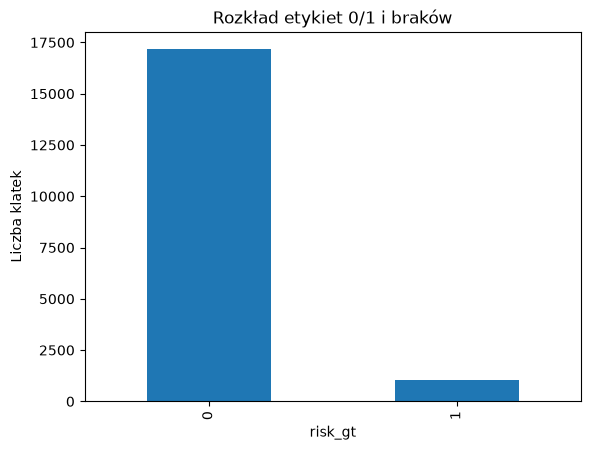

Nie nadpisano istniejącego: /Users/maja/Documents/magisterka/Traffic-Threat-Detection-MSc/outputs/ml_experiment/all_ml_frames.csv (ustaw OVERWRITE=True)


In [76]:
if not data.empty:
    data["risk_gt"].value_counts(dropna=False).sort_index().plot.bar(title="Rozkład etykiet 0/1 i braków")
    plt.xlabel("risk_gt")
    plt.ylabel("Liczba klatek")
    plt.show()

    ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
    combined_path = ARTIFACTS_DIR / "all_ml_frames.csv"
    if combined_path.exists() and not OVERWRITE:
        print(f"Nie nadpisano istniejącego: {combined_path} (ustaw OVERWRITE=True)")
    else:
        data.to_csv(combined_path, index=False)
        print("Zapisano:", combined_path)


## 6. Podział na niezależne zdarzenia WTS

Ten etap wykonaj dopiero z odpowiednią liczbą oznaczonych scen. Klatki z tego samego `source_event_id` nigdy nie mogą trafić do różnych splitów. Zasadą jest zachowanie całych widoków i zdarzeń w jednej grupie.

Przy małym zbiorze 70/15/15 może być niestabilne: traktuj to jako pilotaż, nie jako automatyczny gwarant jakości badań.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

labeled = data.loc[data["risk_gt"].notna() & (data["pipeline_ok"] == 1)].copy() if not data.empty else pd.DataFrame()
split_ready = False
if labeled.empty:
    print("Brak oznaczonych klatek — pomiń trening i wróć po dodaniu etykiet.")
elif labeled["source_event_id"].nunique() < 8:
    print("Mniej niż 10 niezależnych zdarzeń: przygotuj więcej danych przed podziałem.")
elif labeled["risk_gt"].nunique() < 2:
    print("Potrzebne są obie klasy 0 i 1.")
else:
    first = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
    dev_i, test_i = next(first.split(labeled, labeled["risk_gt"], labeled["source_event_id"]))
    dev, test = labeled.iloc[dev_i].copy(), labeled.iloc[test_i].copy()
    second = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=43)
    train_i, val_i = next(second.split(dev, dev["risk_gt"], dev["source_event_id"]))
    train, val = dev.iloc[train_i].copy(), dev.iloc[val_i].copy()

    for name, part in [("train",train), ("validation",val), ("test",test)]:
        print(name, "rows=", len(part), "events=", part.source_event_id.nunique(),
              "labels=", part.risk_gt.value_counts().to_dict())
    groups = [set(d.source_event_id) for d in [train,val,test]]
    assert not (groups[0]&groups[1] or groups[0]&groups[2] or groups[1]&groups[2])
    split_ready = all(p.risk_gt.nunique() == 2 for p in [train,val,test])
    if not split_ready:
        print("STOP: nie wszystkie zbiory mają obie klasy; zmień dobór grup lub zbierz więcej zdarzeń.")


Mniej niż 10 niezależnych zdarzeń: przygotuj więcej danych przed podziałem.


## 7. Pierwszy model: Random Forest (pilotaż)

Trenowanie jest celowo warunkowe. Test służy wyłącznie do końcowej ewaluacji — nie dobieraj na nim hiperparametrów ani progu. Model korzysta z 13 ustalonych cech; braki uzupełnia wewnątrz pipeline'u.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

if split_ready:
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
        ("rf", RandomForestClassifier(n_estimators=200, max_depth=8,
                                      min_samples_leaf=5, class_weight="balanced",
                                      random_state=42, n_jobs=-1)),
    ])
    model.fit(train[FEATURES], train["risk_gt"].astype(int))
    pred_val = model.predict(val[FEATURES])
    print("Walidacja (tylko pilotaż):")
    print(classification_report(val["risk_gt"].astype(int), pred_val, zero_division=0))
    print(confusion_matrix(val["risk_gt"].astype(int), pred_val, labels=[0,1]))
else:
    print("Trening pominięty — brak wystarczająco różnorodnych, niezależnych danych.")


## 8. Porównanie z regułami i końcowy test (uruchom tylko po zamrożeniu modelu)

Ustaw `RUN_FINAL_TEST = True` dopiero kiedy skończysz dobieranie danych, cech, hiperparametrów i progu na walidacji. Końcowy test nie służy do podejmowania dalszych decyzji o modelu.

In [ ]:
RUN_FINAL_TEST = False

if RUN_FINAL_TEST and split_ready:
    from sklearn.metrics import precision_score, recall_score, f1_score
    y = test["risk_gt"].astype(int)
    predictions = {
        "Random Forest": model.predict(test[FEATURES]),
        "Reguły": test["rule_pred"].astype(int).to_numpy(),
    }
    rows = []
    for name, pred in predictions.items():
        rows.append({
            "method": name,
            "precision": precision_score(y,pred,zero_division=0),
            "recall": recall_score(y,pred,zero_division=0),
            "f1": f1_score(y,pred,zero_division=0),
        })
    display(pd.DataFrame(rows))
else:
    print("Końcowy test wyłączony. Uruchom go tylko raz na zamrożonej konfiguracji.")


## Dalsze kroki badawcze

- Zweryfikuj liczbę **niezależnych zdarzeń**, a nie tylko liczbę klatek.
- Sprawdź, czy etykiety `risk_gt` opisują całą scenę w każdej chwili.
- Gdy danych przybędzie, zastosuj grupową walidację krzyżową i sprawdź stabilność wyników.
- Dodaj regresję logistyczną jako prosty baseline ML oraz później eksperyment z dodatkowymi cechami historycznymi.
- Raportuj też skuteczność **na poziomie incydentu**, a nie wyłącznie klatek.
- Zapisz w pracy, skąd pochodzą etykiety (ręczne czy przybliżone z WTS/VQA).